<a href="https://colab.research.google.com/github/pedro1ball/colab-notebooks_new/blob/main/task_numpy_practice_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ №1 СУНЦ МГУ - Numpy practice

**Среда:** Python 3.14.7. Локальные модули `functions.py` и `functions_vectorized.py` повторно импортируются при каждом запуске ячейки с решением.


### Туториальные задачи
__(9 баллов)__

Ниже приведены задачи на работу с numpy-массивами. Для каждой из задач нужно привести 2 реализации: одна без использования numpy (cчитайте, что там, где на входе или выходе должны быть numpy array, будут просто списки), а вторая полностью векторизованная (без использования питоновских циклов/map/list comprehension). Невекторизованная реализация каждой из задач оценивается в __0.5 балла__, векторизованная – в __1 балл__.

Реализации без использования векторизации нужно записать в файл functions.py, а векторизованные &mdash; в файл functions_vectorized.py

Для каждой задачи, приведённой ниже сравните скорость работы невекторизованной и векторизованной реализации. С помощью пакета matplotlib постройте графики времени работы в зависимости от размера данных. __Графики должны выглядеть опрятно!__ То есть должны быть подписаны оси, названия графиков, и т.д. Например, ниже представлены хороший и плохой графики:

In [ ]:
from importlib import reload

import matplotlib.pyplot as plt
import numpy as np

import functions
import functions_vectorized

%matplotlib inline


def reload_solution_modules():
    """Reload the two local solution modules after their files change."""
    reload(functions)
    reload(functions_vectorized)


data_size = np.array([10, 30, 70, 120])
time_non_vectorized = data_size**2 + 10
time_vectorized = data_size**1.5

figure, (axis_bad, axis_good) = plt.subplots(1, 2, figsize=(13, 5))

axis_bad.plot(data_size, time_non_vectorized)
axis_bad.plot(data_size, time_vectorized)
axis_bad.set_title("Плохой график")
axis_bad.set_xlabel("Размер данных")
axis_bad.set_ylabel("Время")

axis_good.plot(data_size, time_non_vectorized, label="Невекторизованная")
axis_good.plot(data_size, time_vectorized, label="Векторизованная")
axis_good.set_title("Хороший график")
axis_good.set_xlabel("Длина массива")
axis_good.set_ylabel("Время (с)")
axis_good.grid(True, alpha=0.3)
axis_good.legend()

figure.tight_layout()
plt.show()


SyntaxError: invalid syntax (functions.py, line 12)

* __Задача 1__: Подсчитать произведение ненулевых элементов на диагонали прямоугольной матрицы.  
 Например, для X = np.array([[1, 0, 1], [2, 0, 2], [3, 0, 3], [4, 4, 4]]) ответ – 3.

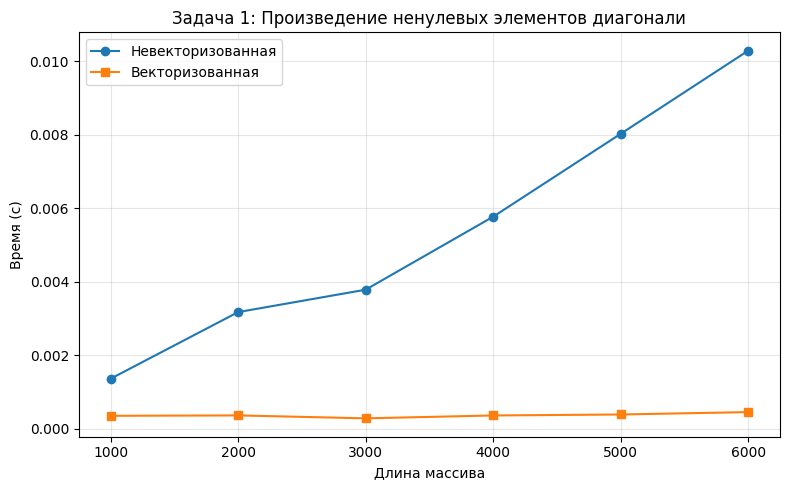

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

def get_non_zero_diag_product(matrix):
    product = 1
    n = min(len(matrix), len(matrix[0]))
    for i in range(n):
        if matrix[i][i] != 0:
            product *= matrix[i][i]
    return product

def get_non_zero_diag_product_vec(matrix):
    diag = np.diagonal(matrix)
    non_zeros = diag[diag != 0]
    return np.prod(non_zeros)

data_sizes = np.array([1000, 2000, 3000, 4000, 5000, 6000])
time_non_vectorized = []
time_vectorized = []

for N in data_sizes:
    matrix_np = np.random.randint(0, 10, size=(N, N + 50))
    matrix_list = matrix_np.tolist()


    matrix_np2 = np.random.randint(0, 10, size=(N, N + 50))
    matrix_list2 = matrix_np2.tolist()



    matrix_np3 = np.random.randint(0, 10, size=(N, N + 50))
    matrix_list3 = matrix_np3.tolist()

    start = time.perf_counter()
    get_non_zero_diag_product(matrix_list)
    get_non_zero_diag_product(matrix_list2)


    get_non_zero_diag_product(matrix_list3)

    time_non_vectorized.append((time.perf_counter() - start))


    start = time.perf_counter()
    get_non_zero_diag_product_vec(matrix_np)
    get_non_zero_diag_product_vec(matrix_np2)
    get_non_zero_diag_product_vec(matrix_np3)

    time_vectorized.append((time.perf_counter() - start))

plt.figure(figsize=(8, 5))
plt.plot(data_sizes, time_non_vectorized, marker='o', label="Невекторизованная")
plt.plot(data_sizes, time_vectorized, marker='s', label="Векторизованная")

plt.title("Задача 1: Произведение ненулевых элементов диагонали")
plt.xlabel("Длина массива")
plt.ylabel("Время (с)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()



* __Задача 2__: Даны два вектора x и y. Проверить, задают ли они одно и то же мультимножество.  
  Например, для x = np.array([1, 2, 2, 4]), y = np.array([4, 2, 1, 2]) ответ – True.
  
  


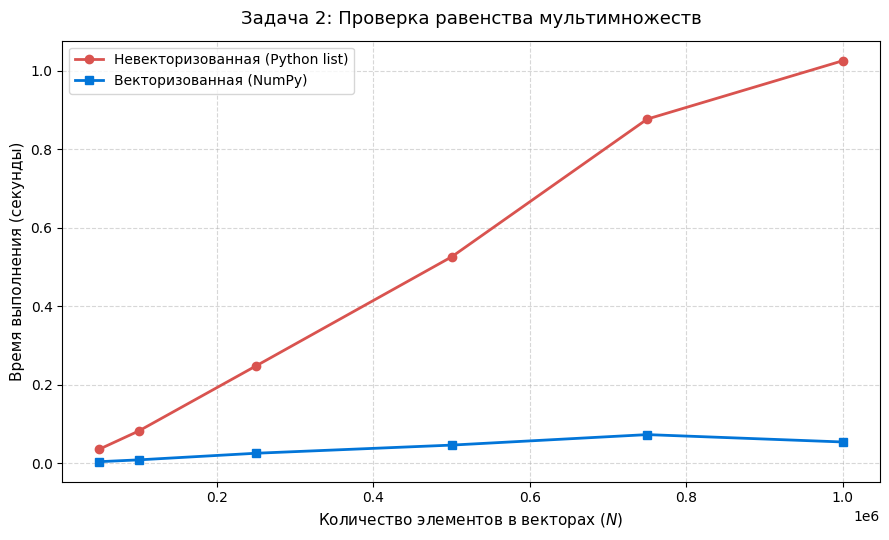

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np


def are_multisets_equal(x, y):
    if len(x) != len(y):
        return False
    return sorted(x) == sorted(y)

def are_multisets_equal_vec(x, y):
    return np.array_equal(np.sort(x), np.sort(y))

data_sizes = [50_000, 100_000, 250_000, 500_000, 750_000, 1_000_000]

times_pure_python = []
times_numpy = []

for n in data_sizes:
    x_np = np.random.randint(0, 100_000, size=n)
    y_np = np.random.permutation(x_np)

    x_list = x_np.tolist()
    y_list = y_np.tolist()

    start = time.perf_counter()
    are_multisets_equal(x_list, y_list)
    times_pure_python.append(time.perf_counter() - start)

    start = time.perf_counter()
    are_multisets_equal_vec(x_np, y_np)
    times_numpy.append(time.perf_counter() - start)

plt.figure(figsize=(9, 5.5), dpi=100)

plt.plot(
    data_sizes,
    times_pure_python,
    marker='o',
    color='#d9534f',
    linewidth=2,
    label='Невекторизованная (Python list)'
)
plt.plot(
    data_sizes,
    times_numpy,
    marker='s',
    color='#0275d8',
    linewidth=2,
    label='Векторизованная (NumPy)'
)

plt.title('Задача 2: Проверка равенства мультимножеств', fontsize=13, pad=12)
plt.xlabel('Количество элементов в векторах ($N$)', fontsize=11)
plt.ylabel('Время выполнения (секунды)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

plt.show()

* __Задача 3__: Найти максимальный элемент в векторе x среди элементов, перед которыми стоит нулевой.  
 Например, для x = np.array([6, 2, 0, 3, 0, 0, 5, 7, 0]) ответ – 5.

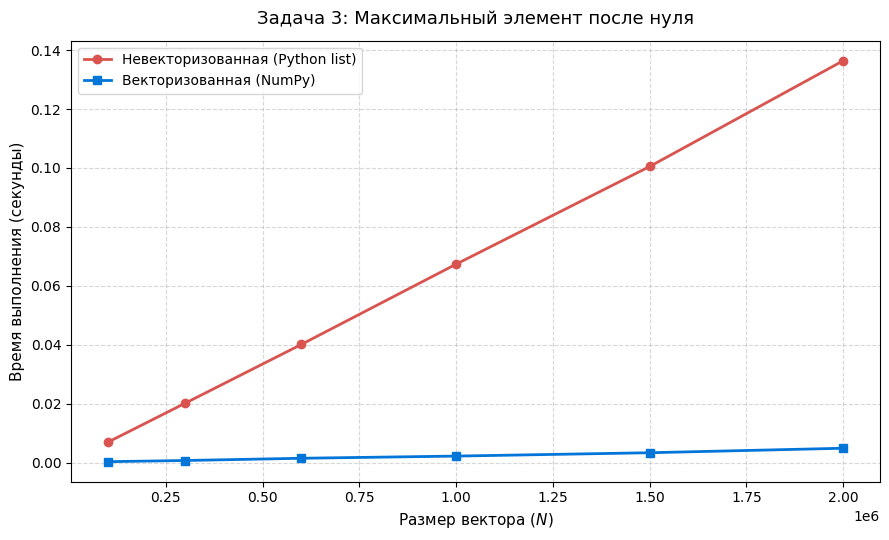

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np

def max_element_after_zero(x):
    max_val = None
    for i in range(1, len(x)):
        if x[i - 1] == 0:
            if max_val is None or x[i] > max_val:
                max_val = x[i]
    return max_val

def max_element_after_zero_vec(x):
    mask = (x[:-1] == 0)
    return np.max(x[1:][mask])

data_sizes = [100000, 300000, 600000, 1000000, 1500000, 2000000]

times_python = []
times_numpy = []

for n in data_sizes:
    # можно конечно рандомить число нулей от 0 до n, генерить список, а потом шафлить, но и так сойдет
    x_np = np.random.randint(0, 50, size=n)
    x_list = x_np.tolist()

    start = time.perf_counter()
    max_element_after_zero(x_list)
    times_python.append(time.perf_counter() - start)

    start = time.perf_counter()
    max_element_after_zero_vec(x_np)
    times_numpy.append(time.perf_counter() - start)

# график
plt.figure(figsize=(9, 5.5), dpi=100)

plt.plot(
    data_sizes,
    times_python,
    marker='o',
    color='#d9534f',
    linewidth=2,
    label='Невекторизованная (Python list)'
)
plt.plot(
    data_sizes,
    times_numpy,
    marker='s',
    color='#0275d8',
    linewidth=2,
    label='Векторизованная (NumPy)'
)

plt.title('Задача 3: Максимальный элемент после нуля', fontsize=13, pad=12)
plt.xlabel('Размер вектора ($N$)', fontsize=11)
plt.ylabel('Время выполнения (секунды)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

plt.show()



* __Задача 4__: Дан трёхмерный массив, содержащий изображение, размера (height, width, numChannels), а также вектор длины numChannels. Сложить каналы изображения с указанными весами, и вернуть результат в виде матрицы размера (height, width). В ноутбуке приведите пример работы функции – преобразуйте цветное изображение в оттенки серого, использовав коэффициенты np.array([0.299, 0.587, 0.114]). Считать реальное изображение можно с помощью `PIL.Image.open` из пакета Pillow: `img = np.asarray(Image.open(path).convert("RGB"))`. Устаревшая функция `scipy.misc.imread` удалена из современных версий SciPy.


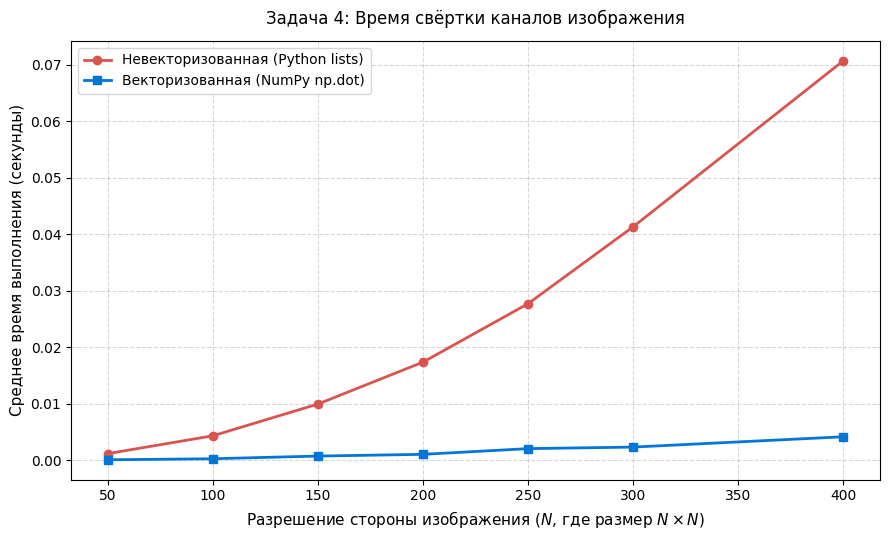

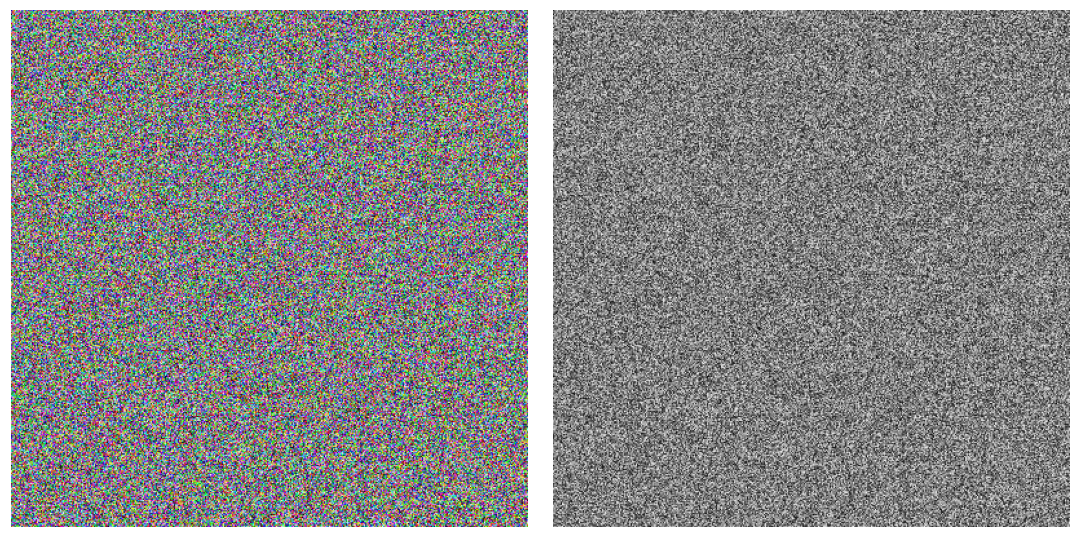

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

def convert_image_py(image, weights):
    height = len(image)
    width = len(image[0])
    num_channels = len(weights)
    result = []
    for i in range(height):
        row = []
        for j in range(width):
            pixel_val = 0.0
            for c in range(num_channels):
                pixel_val += image[i][j][c] * weights[c]
            row.append(pixel_val)
        result.append(row)
    return result

def convert_image_vec(image, weights):
    return np.dot(image, weights)

image_sizes = [50, 100, 150, 200, 250, 300, 400]
weights_np = np.array([0.299, 0.587, 0.114])
weights_list = weights_np.tolist()

NUM_RUNS = 3
times_python_avg = []
times_numpy_avg = []

for n in image_sizes:
    run_py = []
    run_vec = []

    for _ in range(NUM_RUNS):
        img_np = np.random.randint(0, 256, size=(n, n, 3), dtype=np.uint8)
        img_list = img_np.tolist()

        start = time.perf_counter()
        convert_image_py(img_list, weights_list)
        run_py.append(time.perf_counter() - start)

        start = time.perf_counter()
        convert_image_vec(img_np, weights_np)
        run_vec.append(time.perf_counter() - start)

    times_python_avg.append(np.mean(run_py))
    times_numpy_avg.append(np.mean(run_vec))

plt.figure(figsize=(9, 5.5), dpi=100)

plt.plot(
    image_sizes,
    times_python_avg,
    marker='o',
    color='#d9534f',
    linewidth=2,
    label='Невекторизованная (Python lists)'
)
plt.plot(
    image_sizes,
    times_numpy_avg,
    marker='s',
    color='#0275d8',
    linewidth=2,
    label='Векторизованная (NumPy np.dot)'
)

plt.title('Задача 4: Время свёртки каналов изображения', fontsize=12, pad=12)
plt.xlabel('Разрешение стороны изображения ($N$, где размер $N \\times N$)', fontsize=11)
plt.ylabel('Среднее время выполнения (секунды)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

last_gray_img = convert_image_vec(img_np, weights_np)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=110)

axes[0].imshow(img_np)
axes[0].axis("off")

axes[1].imshow(last_gray_img, cmap="gray")
axes[1].axis("off")

plt.tight_layout()
plt.show()

* __Задача 5__: Реализовать кодирование длин серий (Run-length encoding). Для некоторого вектора x необходимо вернуть кортеж из двух векторов одинаковой длины. Первый содержит числа, а второй - сколько раз их нужно повторить.  
 Например, для x = np.array([2, 2, 2, 3, 3, 3, 5]) ответ – (np.array([2, 3, 5]), np.array([3, 3, 1])).

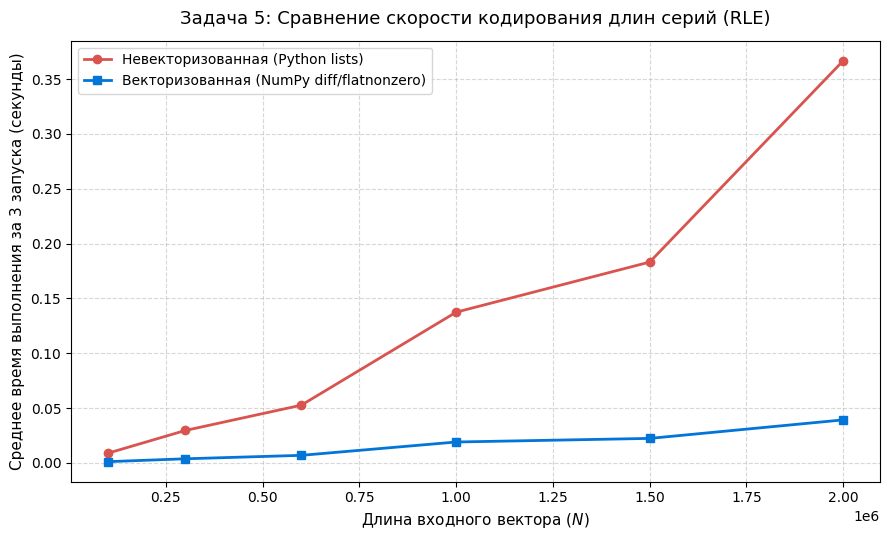

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np

def run_length_encoding(x):
    values = [x[0]]
    counts = [1]
    for val in x[1:]:
        if val == values[-1]:
            counts[-1] += 1
        else:
            values.append(val)
            counts.append(1)
    return values, counts

def run_length_encoding_vec(x):
    mask = np.concatenate(([True], x[1:] != x[:-1]))
    values = x[mask]
    idx = np.flatnonzero(mask)
    counts = np.diff(np.concatenate((idx, [len(x)])))
    return values, counts

data_sizes = [100_000, 300_000, 600_000, 1_000_000, 1_500_000, 2_000_000]
NUM_RUNS = 3

times_py_avg = []
times_vec_avg = []

for n in data_sizes:
    run_py = []
    run_vec = []

    for _ in range(NUM_RUNS):
        #  длинные непрерывные серии
        x_np = np.random.randint(0, 5, size=n)
        x_list = x_np.tolist()

        start = time.perf_counter()
        run_length_encoding(x_list)
        run_py.append(time.perf_counter() - start)

        start = time.perf_counter()
        run_length_encoding_vec(x_np)
        run_vec.append(time.perf_counter() - start)

    times_py_avg.append(np.mean(run_py))
    times_vec_avg.append(np.mean(run_vec))

plt.figure(figsize=(9, 5.5), dpi=100)

plt.plot(
    data_sizes,
    times_py_avg,
    marker='o',
    color='#d9534f',
    linewidth=2,
    label='Невекторизованная (Python lists)'
)
plt.plot(
    data_sizes,
    times_vec_avg,
    marker='s',
    color='#0275d8',
    linewidth=2,
    label='Векторизованная (NumPy diff/flatnonzero)'
)

plt.title('Задача 5: Сравнение скорости кодирования длин серий (RLE)', fontsize=13, pad=12)
plt.xlabel('Длина входного вектора ($N$)', fontsize=11)
plt.ylabel('Среднее время выполнения за 3 запуска (секунды)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

plt.show()



* __Задача 6__: Даны две выборки объектов - X и Y. Вычислить матрицу евклидовых расстояний между объектами. Дополнительно сравните с функцией scipy.spatial.distance.cdist по скорости работы (сравнения приведите ниже в ноутбуке).

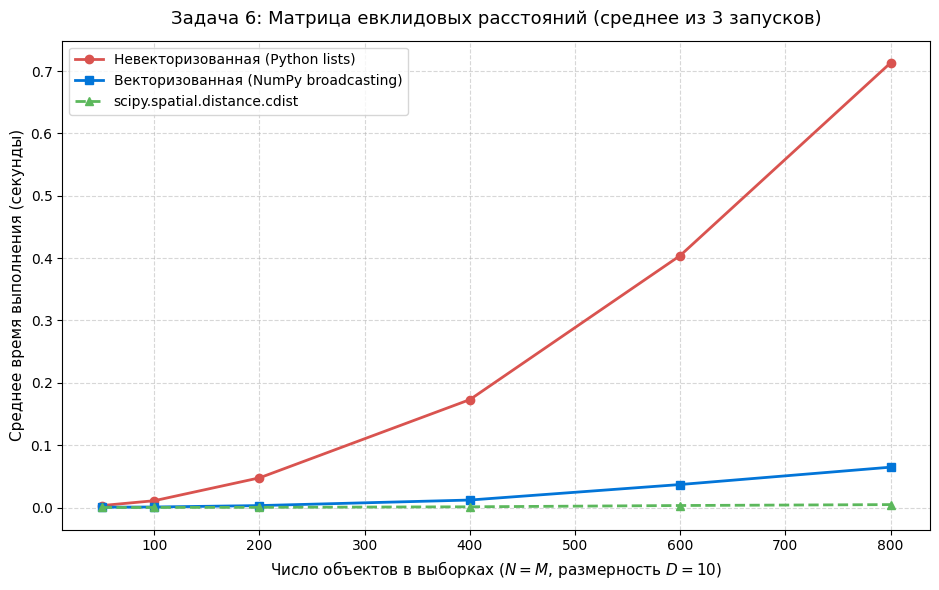

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.distance import cdist

def pairwise_distance_py(x, y):
    n = len(x)
    m = len(y)
    d = len(x[0])
    result = []
    for i in range(n):
        row = []
        for j in range(m):
            dist_sq = 0.0
            for k in range(d):
                diff = x[i][k] - y[j][k]
                dist_sq += diff * diff
            row.append(dist_sq ** 0.5)
        result.append(row)
    return result

def pairwise_distance_vec(x, y):
    # n 1 D
    # 1 m D
    #превращается в N M D а после в [i, j] лежит разность по D размерностям
    return np.linalg.norm(x[:, np.newaxis, :] - y[np.newaxis, :, :], axis=2)

data_sizes = [50, 100, 200, 400, 600, 800]
d_features = 10
NUM_RUNS = 3

times_py_avg = []
times_vec_avg = []
times_scipy_avg = []

for n in data_sizes:
    run_py = []
    run_vec = []
    run_scipy = []

    for _ in range(NUM_RUNS):
        x_np = np.random.randn(n, d_features)
        y_np = np.random.randn(n, d_features)

        x_list = x_np.tolist()
        y_list = y_np.tolist()

        start = time.perf_counter()
        pairwise_distance_py(x_list, y_list)
        run_py.append(time.perf_counter() - start)

        start = time.perf_counter()
        pairwise_distance_vec(x_np, y_np)
        run_vec.append(time.perf_counter() - start)

        start = time.perf_counter()
        cdist(x_np, y_np, metric='euclidean')
        run_scipy.append(time.perf_counter() - start)

    times_py_avg.append(np.mean(run_py))
    times_vec_avg.append(np.mean(run_vec))
    times_scipy_avg.append(np.mean(run_scipy))

plt.figure(figsize=(9.5, 6), dpi=100)

plt.plot(
    data_sizes,
    times_py_avg,
    marker='o',
    color='#d9534f',
    linewidth=2,
    label='Невекторизованная (Python lists)'
)
plt.plot(
    data_sizes,
    times_vec_avg,
    marker='s',
    color='#0275d8',
    linewidth=2,
    label='Векторизованная (NumPy broadcasting)'
)
plt.plot(
    data_sizes,
    times_scipy_avg,
    marker='^',
    color='#5cb85c',
    linewidth=2,
    linestyle='--',
    label='scipy.spatial.distance.cdist'
)

plt.title('Задача 6: Матрица евклидовых расстояний (среднее из 3 запусков)', fontsize=13, pad=12)
plt.xlabel('Число объектов в выборках ($N = M$, размерность $D = 10$)', fontsize=11)
plt.ylabel('Среднее время выполнения (секунды)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

plt.show()

### Туториал по Markdown

__(1 балл)__

Напишите краткий (а в данной домашке ещё и почти бесмысленный) отчёт с использованием 4-5 различных вариантов разметки/выделения текста.

### Отчёт о вычислительных экспериментах                 ###

В ходе выполнения лабораторной работы мы выяснили, что
**NumPy работает значительно быстрее**,                 
что стало ~~абсолютной неожиданностью~~                 
вполне ожидаемым фактом.

Ключевые наблюдения:                                    
* Цикл `for` тратит *много тактов процессора*.          

> **Главный вывод:** писать векторизованный код      
гораздо быстрее и короче.
